In [9]:
# GridSearchCV(
#     estimator,             # Model yang digunakan (misalnya, LinearRegression())
#     param_grid,            # Dictionary parameter yang akan diuji
#     scoring=None,          # Metrik evaluasi (default = accuracy untuk klasifikasi, r2 untuk regresi)
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     cv=None,               # Jumlah cross-validation (misalnya, 5 untuk 5-fold CV)
#     verbose=0,             # Level output log (0=diam, 1=beberapa info, 2=detail)
#     refit=True,            # Re-train model dengan parameter terbaik
#     return_train_score=False  # Jika True, hasil training score juga ditampilkan
# )

In [10]:
# RandomizedSearchCV(
#     estimator,             # Model yang digunakan
#     param_distributions,   # Dictionary parameter yang akan diuji (dipilih secara acak)
#     n_iter=10,             # Jumlah kombinasi parameter yang diuji
#     scoring=None,          # Metrik evaluasi (default = accuracy untuk klasifikasi, r2 untuk regresi)
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     cv=None,               # Jumlah cross-validation
#     random_state=None,     # Seed agar hasil tetap sama setiap eksekusi
#     verbose=0,             # Level output log
#     refit=True,            # Re-train model dengan parameter terbaik
#     return_train_score=False  # Jika True, hasil training score juga ditampilkan
# )

In [11]:
# BayesSearchCV(
#     estimator,             # Model yang digunakan
#     search_spaces,         # Dictionary parameter yang akan diuji
#     n_iter=50,             # Jumlah iterasi pencarian
#     scoring=None,          # Metrik evaluasi
#     n_jobs=-1,             # Gunakan semua CPU untuk mempercepat pencarian
#     cv=5,                  # Jumlah cross-validation
#     random_state=None,     # Seed agar hasil tetap sama
#     verbose=0,             # Level output log
#     refit=True             # Re-train model dengan parameter terbaik
# )

In [12]:
# HalvingGridSearchCV(
#     estimator,             # Model yang digunakan
#     param_grid,            # Dictionary parameter yang akan diuji
#     factor=3,              # Setiap iterasi, hanya 1/3 kandidat yang dipertahankan
#     min_resources='exhaust',  # Minimum data yang digunakan sebelum seleksi dilakukan
#     scoring=None,          # Metrik evaluasi
#     cv=None,               # Jumlah cross-validation
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     random_state=None,     # Seed agar hasil tetap sama
#     verbose=0,             # Level output log
#     refit=True             # Re-train model dengan parameter terbaik
# )

Cross validation

In [13]:
# from sklearn.model_selection import KFold

# kf = KFold(
#     n_splits=5,      # Jumlah fold (default = 5)
#     shuffle=False,   # Apakah data diacak sebelum dibagi (default = False)
#     random_state=None  # Seed untuk reproducibility
# )

In [14]:
# from sklearn.model_selection import StratifiedKFold

# skf = StratifiedKFold(
#     n_splits=5,      # Jumlah fold (default = 5)
#     shuffle=True,    # Apakah data diacak sebelum dibagi (default = False)
#     random_state=42  # Seed untuk reproducibility
# )

In [15]:
# from sklearn.model_selection import ShuffleSplit

# ss = ShuffleSplit(
#     n_splits=5,      # Jumlah iterasi pembagian (default = 10)
#     test_size=0.2,   # Proporsi data uji (20% dari dataset)
#     train_size=None, # Proporsi data latih (None = otomatis sisanya)
#     random_state=42  # Seed untuk reproducibility
# )

In [16]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score, ShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from skopt import BayesSearchCV
from collections import Counter
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.metrics import r2_score

df = pd.read_csv("tesla.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500


In [17]:
x = df[['Open', 'High', 'Low']]
y = df['Close']

scaler_x = MinMaxScaler()
x_encode = scaler_x.fit_transform(x)

scaler_y = MinMaxScaler() 
y = scaler_y.fit_transform(y.values.reshape(-1, 1)).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y, 
                                                    test_size=0.3, 
                                                    random_state=42)

FUNCTION

In [18]:
def tuning_model(model, param):
    sf = ShuffleSplit(n_splits=5, test_size=0.3, random_state=42)

    grid_search = GridSearchCV(model, param, cv=sf, scoring='r2', n_jobs=-1)
    grid_search.fit(x_train, y_train)

    random_search = RandomizedSearchCV(model, param_distributions=param, 
                                    n_iter=4, 
                                    cv=sf, 
                                    scoring='r2', 
                                    n_jobs=-1, 
                                    random_state=42)

    random_search.fit(x_train, y_train)


    bayes_search = BayesSearchCV(model, param, cv=sf, 
                                scoring='r2', 
                                n_iter=4, 
                                n_jobs=-1, 
                                random_state=42)

    bayes_search.fit(x_train, y_train)

    hyperband = HalvingGridSearchCV(model, param, cv=sf, 
                                    factor=2, 
                                    scoring='r2', 
                                    n_jobs=-1)

    hyperband.fit(x_train, y_train)
    
    best_params_list = [
        grid_search.best_params_,
        random_search.best_params_,
        bayes_search.best_params_,
        hyperband.best_params_
    ]

    aggregated_params = {key: [params[key] for params in best_params_list] for key in param.keys()}
    
    return aggregated_params
    

HYPERPARAMETER LINEAR REGRESSION, DT, RF, KNN

In [19]:
model_linear = LinearRegression()
model_dt = DecisionTreeRegressor(random_state=42)
model_rf = RandomForestRegressor(random_state=42)
model_knn = KNeighborsRegressor()

param_grid_linear = {
    'fit_intercept': [True, False],
    'copy_X': [True, False],
}

param_grid_dt = {
    'criterion': ['friedman_mse', 'poisson'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'ccp_alpha' : [0, 0.05, 0.1]
}

param_grid_rf = {
    'criterion': ['squared_error', 'poisson'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False],
    'ccp_alpha': [0, 0.05, 0.1]
}

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree'],
    'p': (1, 2)  # 1: Manhattan distance, 2: Euclidean distance
}

best_params_linear = tuning_model(model_linear, param_grid_linear)
best_params_dt = tuning_model(model_dt, param_grid_dt)
best_params_rf = tuning_model(model_rf, param_grid_rf)
best_params_knn = tuning_model(model_knn, param_grid_knn)

fit_intercept, copy_X = (
    Counter(best_params_linear["fit_intercept"]).most_common(1)[0][0],
    Counter(best_params_linear["copy_X"]).most_common(1)[0][0]
)

criterion_dt, max_depth_dt, max_features_dt, min_samples_leaf_dt, min_samples_split_dt, ccp_alpha_dt = (
    Counter(best_params_dt["criterion"]).most_common(1)[0][0],
    Counter(best_params_dt["max_depth"]).most_common(1)[0][0],
    Counter(best_params_dt["max_features"]).most_common(1)[0][0],
    Counter(best_params_dt["min_samples_leaf"]).most_common(1)[0][0],
    Counter(best_params_dt["min_samples_split"]).most_common(1)[0][0],
    Counter(best_params_dt["ccp_alpha"]).most_common(1)[0][0]
)

criterion_rf, max_depth_rf, max_features_rf, min_samples_leaf_rf, min_samples_split_rf, bootstrap, ccp_alpha_rf = (
    Counter(best_params_rf["criterion"]).most_common(1)[0][0],
    Counter(best_params_rf["max_depth"]).most_common(1)[0][0],
    Counter(best_params_rf["max_features"]).most_common(1)[0][0],
    Counter(best_params_rf["min_samples_leaf"]).most_common(1)[0][0],
    Counter(best_params_rf["min_samples_split"]).most_common(1)[0][0],
    Counter(best_params_rf["bootstrap"]).most_common(1)[0][0],
    Counter(best_params_rf["ccp_alpha"]).most_common(1)[0][0]
)

n_neighbors, weights, algorithm, p = (
    Counter(best_params_knn["n_neighbors"]).most_common(1)[0][0],
    Counter(best_params_knn["weights"]).most_common(1)[0][0],
    Counter(best_params_knn["algorithm"]).most_common(1)[0][0],
    Counter(best_params_knn["p"]).most_common(1)[0][0]
)

/opt/anaconda3/lib/python3.12/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


TRAINING MODEL LINEAR, DT, RF, KNN

In [20]:
best_model_linear = LinearRegression(copy_X=copy_X, fit_intercept=fit_intercept)

best_model_dt = DecisionTreeRegressor(criterion=criterion_dt,
                                   max_depth=max_depth_dt, 
                                   max_features=max_features_dt,
                                   min_samples_leaf=min_samples_leaf_dt,
                                   min_samples_split=min_samples_split_dt,
                                   ccp_alpha=ccp_alpha_dt,
                                   random_state=42)

best_model_rf = RandomForestRegressor(
    n_estimators=200,
    criterion=criterion_rf,
    max_depth=max_depth_rf, 
    max_features=max_features_rf,
    min_samples_leaf=min_samples_leaf_rf,
    min_samples_split=min_samples_split_rf,
    bootstrap=bootstrap,
    ccp_alpha=ccp_alpha_rf,
    random_state=42,
    n_jobs=-1
)

best_model_knn = KNeighborsRegressor(
    n_neighbors=n_neighbors,
    weights=weights,
    algorithm=algorithm,
    p=p
)

best_model_linear.fit(x_train, y_train)
best_model_dt.fit(x_train, y_train)
best_model_rf.fit(x_train, y_train)
best_model_knn.fit(x_train, y_train)

y_pred_linear = best_model_linear.predict(x_test)
y_pred_dt = best_model_dt.predict(x_test)
y_pred_rf = best_model_rf.predict(x_test)
y_pred_knn = best_model_knn.predict(x_test)

r2_linear = r2_score(y_test, y_pred_linear)
r2_dt = r2_score(y_test, y_pred_dt)
r2_rf = r2_score(y_test, y_pred_rf)
r2_knn = r2_score(y_test, y_pred_knn)

print(f"R² Score linear: {r2_linear:.5f}")
print(f"R² Score decision tree: {r2_dt:.5f}")
print(f"R² Score random forest: {r2_rf:.5f}")
print(f"R² Score knn: {r2_knn:.5f}")

R² Score linear: 0.99972
R² Score decision tree: 0.99911
R² Score random forest: 0.99946
R² Score knn: 0.99954


CEK OVERFITTING

In [21]:
y_train_pred_linear = best_model_linear.predict(x_train)
y_train_pred_dt = best_model_dt.predict(x_train)
y_train_pred_rf = best_model_rf.predict(x_train)
y_train_pred_knn = best_model_knn.predict(x_train)

r2_train_linear = r2_score(y_train, y_train_pred_linear)
r2_train_dt = r2_score(y_train, y_train_pred_dt)
r2_train_rf = r2_score(y_train, y_train_pred_rf)
r2_train_knn = r2_score(y_train, y_train_pred_knn)

print(f"R² Linear Score Training & Testing: [{r2_train_linear}, {r2_linear}]")
print(f"R² DT Score Training & Testing: [{r2_train_dt}, {r2_dt}]")
print(f"R² RF Score Training & Testing: [{r2_train_rf}, {r2_rf}]")
print(f"R² KNN Score Training & Testing: [{r2_train_knn}, {r2_knn}]")

R² Linear Score Training & Testing: [0.9997444807949968, 0.9997162822341232]
R² DT Score Training & Testing: [0.9999321584095449, 0.9991056580927504]
R² RF Score Training & Testing: [0.9999140303120472, 0.9994643092835294]
R² KNN Score Training & Testing: [1.0, 0.9995373910005084]


In [22]:
sf = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)

score_linear = cross_val_score(best_model_linear, x_encode, y, cv=sf, scoring='r2')
score_dt = cross_val_score(best_model_dt, x_encode, y, cv=sf, scoring='r2')
score_rf = cross_val_score(best_model_rf, x_encode, y, cv=sf, scoring='r2')
score_knn = cross_val_score(best_model_knn, x_encode, y, cv=sf, scoring='r2')

print(f"R² Linear Cross Validation Scores : {score_linear}")
print(f"R² DT Cross Validation Scores : {score_dt}")
print(f"R² RF Cross Validation Scores : {score_rf}")
print(f"R² KNN Cross Validation Scores : {score_knn}")

R² Linear Cross Validation Scores : [0.99964963 0.99979626 0.99964953 0.99973538 0.99974524]
R² DT Cross Validation Scores : [0.99935825 0.99923999 0.99928311 0.99908865 0.99945056]
R² RF Cross Validation Scores : [0.99951554 0.99948314 0.99944361 0.99948432 0.99954926]
R² KNN Cross Validation Scores : [0.99948265 0.99955232 0.9993271  0.99957747 0.99962565]


In [23]:
comparison_df = pd.DataFrame({
    'Actual': scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel(),
    'Predicted Linear': scaler_y.inverse_transform(y_pred_linear.reshape(-1, 1)).ravel(),
    'Predicted DT': scaler_y.inverse_transform(y_pred_dt.reshape(-1, 1)).ravel(),
    'Predicted RF': scaler_y.inverse_transform(y_pred_rf.reshape(-1, 1)).ravel(),
    'Predicted KNN': scaler_y.inverse_transform(y_pred_knn.reshape(-1, 1)).ravel(),
})

comparison_df

,Actual,Predicted Linear,Predicted DT,Predicted RF,Predicted KNN
0,59.860001,60.809207,60.270834,60.593090,61.020478
1,45.122002,45.633119,45.246385,45.325930,45.771537
2,46.882000,48.114413,48.235857,47.744750,47.691544
3,43.686001,43.738921,43.943913,43.825240,43.721973
4,55.318001,54.695217,53.844000,54.216000,54.247634
...,...,...,...,...,...
882,41.080002,40.803264,40.399600,40.748961,40.877156
883,39.130001,39.690242,40.399600,39.970520,40.187324
884,161.882004,165.245636,166.878998,165.433049,163.220046
885,7.398000,7.506471,7.323333,7.311790,7.277166


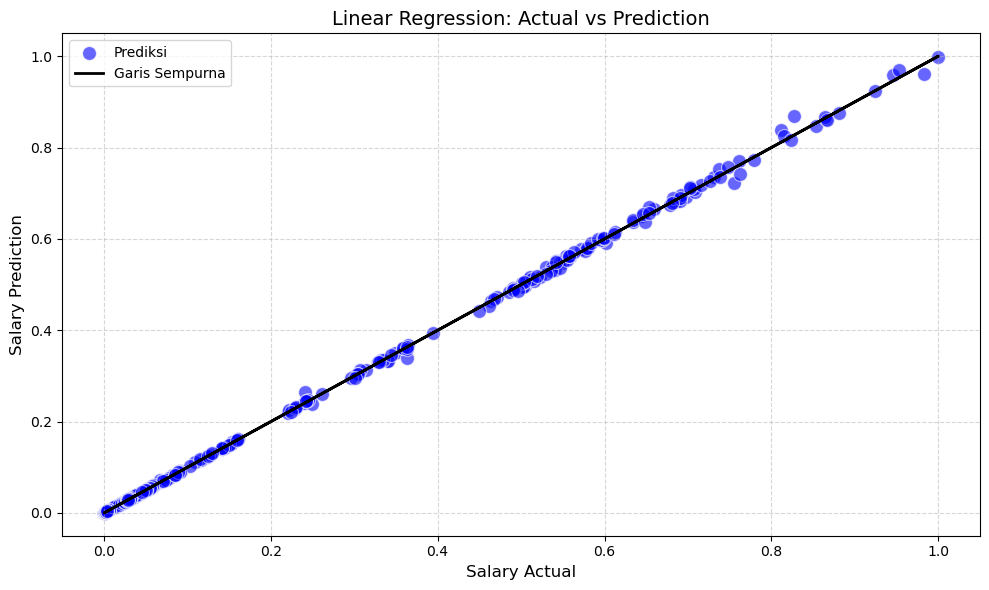

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

y_test_1d = np.ravel(y_test)
y_pred_1d = np.ravel(y_pred_linear)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_1d, y=y_pred_1d, color='blue', alpha=0.6, s=100, label='Prediksi')
plt.plot(y_test_1d, y_test_1d, color='black', linewidth=2, label='Garis Sempurna')
plt.xlabel('Salary Actual', fontsize=12)
plt.ylabel('Salary Prediction', fontsize=12)
plt.title('Linear Regression: Actual vs Prediction', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Assignment

In [25]:
def tuning_model(model, param, x, y):
    sf = ShuffleSplit(n_splits=5, test_size=0.3, random_state=42)

    grid_search = GridSearchCV(model, param, cv=sf, scoring='r2', n_jobs=-1)
    grid_search.fit(x, y)

    random_search = RandomizedSearchCV(model, param_distributions=param, 
                                    n_iter=4, 
                                    cv=sf, 
                                    scoring='r2', 
                                    n_jobs=-1, 
                                    random_state=42)

    random_search.fit(x, y)


    bayes_search = BayesSearchCV(model, param, cv=sf, 
                                scoring='r2', 
                                n_iter=4, 
                                n_jobs=-1, 
                                random_state=42)

    bayes_search.fit(x, y)

    hyperband = HalvingGridSearchCV(model, param, cv=sf, 
                                    factor=2, 
                                    scoring='r2', 
                                    n_jobs=-1)

    hyperband.fit(x, y)
    
    best_params_list = [
        grid_search.best_params_,
        random_search.best_params_,
        bayes_search.best_params_,
        hyperband.best_params_
    ]

    aggregated_params = {key: [params[key] for params in best_params_list] for key in param.keys()}
    
    return aggregated_params
    


In [26]:
import numpy as np
import pandas as pd

def SafeCleaner(data, dummy_columns=None):
    """
    Membersihkan DataFrame, Series, atau ndarray:
    - Dummy columns (0/1) NaN -> 0 (hanya untuk DataFrame)
    - Numeric columns NaN -> imputasi mean
    - Inf/-inf -> aman dengan np.nan_to_num()
    
    Params:
        data: DataFrame, Series, atau ndarray
        dummy_columns: list kolom dummy (optional, hanya untuk DataFrame)
        
    Returns:
        Data bersih (sama tipe inputnya)
    """
    
    # Kalau data adalah DataFrame
    if isinstance(data, pd.DataFrame):
        df_clean = data.copy()
        
        # 1. Untuk kolom dummy: NaN -> 0
        if dummy_columns is not None:
            for col in dummy_columns:
                if col in df_clean.columns:
                    df_clean[col] = df_clean[col].fillna(0)
        
        # 2. Untuk kolom numeric lain: NaN -> imputasi mean
        numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
        for col in numeric_cols:
            if dummy_columns is None or col not in dummy_columns:
                mean_val = df_clean[col].mean()
                df_clean[col] = df_clean[col].fillna(mean_val)
        
        # 3. Tangani inf dan -inf
        df_clean = df_clean.replace([np.inf, -np.inf], np.nan)
        df_clean = df_clean.apply(lambda x: np.nan_to_num(x) if x.dtype.kind in 'fi' else x)
        
        return df_clean

    # Kalau data adalah Series
    elif isinstance(data, pd.Series):
        series_clean = data.copy()
        
        # Ganti inf/-inf ke NaN
        series_clean = series_clean.replace([np.inf, -np.inf], np.nan)
        
        # Isi NaN dengan mean
        mean_val = series_clean.mean()
        series_clean = series_clean.fillna(mean_val)
        
        # Pastikan tidak ada NaN/inf
        series_clean = pd.Series(np.nan_to_num(series_clean), index=series_clean.index)
        
        return series_clean

    # Kalau data adalah numpy array
    elif isinstance(data, np.ndarray):
        return np.nan_to_num(data)
    
    else:
        raise TypeError("Input harus DataFrame, Series, atau ndarray")



In [27]:
df = pd.read_csv('death.csv')
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
675,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
676,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
677,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
678,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [28]:
print(df.isnull().sum())

Cause              0
Type               0
Year               0
Data Redundancy    0
Total Deaths       0
Source             0
Page at Source     2
Source URL         3
dtype: int64


Kalau kolom/bagian punya <5% missing ➔ drop masih aman.

Kalau >20%-30% missing ➔ harus hati-hati, lebih baik imputasi.

In [29]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
675,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
676,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
677,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
678,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [30]:
from baru import outlier

# Membersihkan data
df = outlier(df, "Total Deaths")

# Feature dan target
x = df[['Cause', 'Type']]
y = df[['Total Deaths']]

# Encoding
x_encoded = pd.get_dummies(x, columns=['Cause', 'Type'])
# x_encoded = SafeCleaner(x_encoded, dummy_columns=['Cause', 'Type'])

# Normalisasi target
scaler = MinMaxScaler()
y_norm = scaler.fit_transform(y).ravel()
y_norm = SafeCleaner(y_norm)

# Split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_norm, test_size=0.3, random_state=42)

# Final cleaning setelah split
# x_train = SafeCleaner(x_train)
# x_test = SafeCleaner(x_test)
# y_train = SafeCleaner(y_train)
# y_test = SafeCleaner(y_test)


In [31]:
# 1. Model sebelum tuning
k = 3
model = KNeighborsRegressor(n_neighbors=k)
model.fit(x_train, y_train)

train_score_before = model.score(x_train, y_train)
test_score_before = model.score(x_test, y_test)

print(f"Before Tuning - R² Training: {train_score_before:.5f}, R² Testing: {test_score_before:.5f}")

# 2. Hyperparameter tuning
model2 = KNeighborsRegressor()

param_grid_knn = {
    'n_neighbors': [1,3,5,7],
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree'],
    'p': (1, 2)  # 1: Manhattan distance, 2: Euclidean distance
}

best_params_knn = tuning_model(model2, param_grid_knn, x_train, y_train)

n_neighbors, weights, algorithm, p = (
    Counter(best_params_knn["n_neighbors"]).most_common(1)[0][0],
    Counter(best_params_knn["weights"]).most_common(1)[0][0],
    Counter(best_params_knn["algorithm"]).most_common(1)[0][0],
    Counter(best_params_knn["p"]).most_common(1)[0][0]
)

# 3. Model setelah tuning
best_model_knn = KNeighborsRegressor(
    n_neighbors=n_neighbors,
    weights=weights,
    algorithm=algorithm,
    p=p
)

best_model_knn.fit(x_train, y_train)

train_score_after = best_model_knn.score(x_train, y_train)
test_score_after = best_model_knn.score(x_test, y_test)

print(f"After Tuning - R² Training: {train_score_after:.5f}, R² Testing: {test_score_after:.5f}")

Before Tuning - R² Training: 0.66856, R² Testing: 0.63327
After Tuning - R² Training: 0.78688, R² Testing: 0.70272


In [32]:
sf = ShuffleSplit(n_splits=5, test_size=0.3, random_state=42)
score_knn = cross_val_score(model, x_encoded, y_norm, cv=sf, scoring='r2')
score_knn_best = cross_val_score(best_model_knn, x_encoded, y_norm, cv=sf, scoring='r2')

print(f"R² KNN Cross Validation Scores : {score_knn}")
print(f"R² KNN Cross Validation Scores : {score_knn_best}")

R² KNN Cross Validation Scores : [0.63327265 0.27416087 0.27061897 0.11616273 0.39362253]
R² KNN Cross Validation Scores : [0.70272481 0.39996253 0.36191798 0.36492732 0.30085337]


Soal 

1. gunakan data death.csv
2. lakukan data cleaning outlier, dropna, duplikat.
3. lakukan data preprosesing dan splitting data.
4. lakukan prediksi menggunakan model default knn.
5. carilah parameter terbaik menggunakan metode tuning.
6. gunakan parameter terbaik pada model knn yang baru dan lakukan prediksi.
7. bandingkan skor ketika menggunakan model default dan setelah model di tuning.
